In [29]:
!pip install pandas
!pip install numpy
!pip install seaborn
!pip install scikit-learn


In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
ds = pd.read_csv("uber.csv")

ds.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [32]:
ds.dtypes

Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [33]:
ds.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [34]:
ds.isna().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [35]:
ds.dropna(inplace=True)

In [36]:
ds["pickup_datetime"] = pd.to_datetime(ds["pickup_datetime"])

ds["hour"] = ds["pickup_datetime"].dt.hour

In [37]:
ds = ds.rename(columns={"hour": "time"})

In [38]:
ds.drop("pickup_datetime", axis=1, inplace=True)

In [39]:
ds.drop("Unnamed: 0", axis=1, inplace=True)

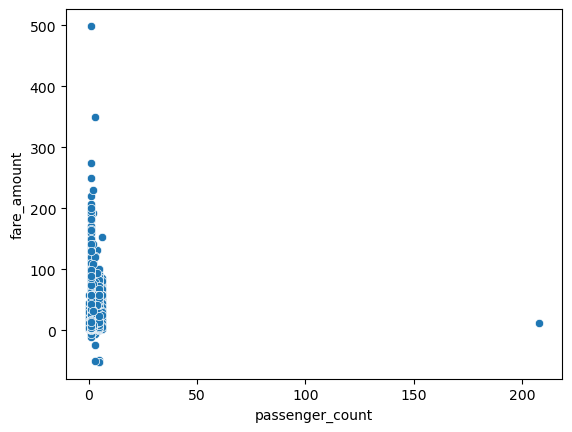

In [40]:
sns.scatterplot(
    data=ds,
    y="fare_amount",
    x="passenger_count"
)

plt.show()

In [41]:
ds = ds[
    (ds["passenger_count"] >= 1) &
    (ds["passenger_count"] <= 6)
]

In [42]:
def remove_outliers(feature):

    for col in feature:

        Q1 = ds[col].quantile(0.25)

        Q3 = ds[col].quantile(0.75)

        IQR = Q3 - Q1

        ds_filtered = ds[
            (ds[col] >= Q1 - 1.5 * IQR) &
            (ds[col] <= Q3 + 1.5 * IQR)
        ]

        ds.drop(ds.index.difference(ds_filtered.index), inplace=True)

In [43]:
cols = [
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude"
]

remove_outliers(cols)

In [44]:
import math

def euclidean_distance(lat1, lon1, lat2, lon2):

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    dis = math.sqrt(dlat**2 + dlon**2)

    return dis

In [45]:
ds["distance"] = ds.apply(
    lambda row: euclidean_distance(
        row["pickup_latitude"],
        row["pickup_longitude"],
        row["dropoff_latitude"],
        row["dropoff_longitude"]
    ),
    axis=1
)

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

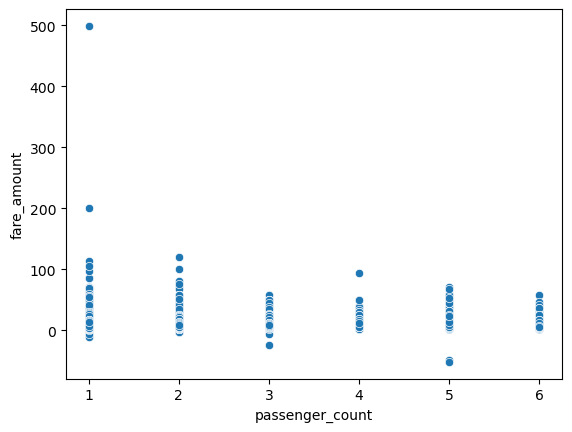

In [46]:
sns.scatterplot(
    data=ds,
    y="fare_amount",
    x="passenger_count"
)

In [47]:
ds = ds[
    ds["passenger_count"].between(1, 6)
]

In [48]:
def remove_outliers(feature):

    global ds

    for col in feature:

        Q1 = ds[col].quantile(0.25)

        Q3 = ds[col].quantile(0.75)

        IQR = Q3 - Q1

        ds = ds[
            (ds[col] >= Q1 - 1.5 * IQR) &
            (ds[col] <= Q3 + 1.5 * IQR)
        ]

In [49]:
cols = [
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude"
]

remove_outliers(cols)

In [50]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

In [54]:
X = ds.drop("fare_amount", axis=1)

X = X.select_dtypes(include=["number"])

y = ds["fare_amount"]

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [56]:
scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)

X_test_scaled = scalar.transform(X_test)

In [57]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [58]:
model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [59]:
y_pred = model.predict(X_test_scaled)

In [60]:
from sklearn.metrics import r2_score, root_mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))

print("RMSE:", root_mean_squared_error(y_test, y_pred))

R2 Score: 0.48961161928627195
RMSE: 3.5026321280771984


In [61]:
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, root_mean_squared_error

In [62]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [63]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [64]:
rf_pred = rf_model.predict(X_test)

In [65]:
print("RF R2 Score:", r2_score(y_test, rf_pred))

print("RF RMSE:", root_mean_squared_error(y_test, rf_pred))

RF R2 Score: 0.5294442499567562
RF RMSE: 3.3631766558639904
